# Semantic Segmentation of a Mars-Analog Landscape with a U-Net


In the autoencoder notebook you built an **encoder–decoder** network that squeezed each image into 16 numbers and rebuilt it. Here we upgrade that design to a **U-Net** for a different job: **mapping terrain units, pixel by pixel**, in drone images of a Mars-analog salt flat in Chile's Atacama Desert.

Think of it as automated geologic mapping. A geologist draws polygons around "salt pan", "ridges", or "wind-blown sand". We will train a network to draw those polygons for us.

### Learning goals
By the end of this lab you should be able to:
1. Explain the difference between **image classification** and **semantic segmentation**.
2. Describe how a labeled segmentation dataset is organized (image + **mask**).
3. Follow how an image flows through a **U-Net** (encoder → bottleneck → decoder, plus skip connections).
4. Train a segmentation model in PyTorch and read its training curves.
5. Evaluate a map with **pixel accuracy**, **IoU**, and a **confusion matrix**, and explain *why* the model gets some terrains wrong.



---
## Step 0: Setup
Run the next two cells once. The first imports libraries. The second holds every setting ("knob") you might want to change, all in one place.

In [3]:
import glob
import os
import re
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() 
else 'mps' if torch.backends.mps.is_available()
else 'cpu')
print(f'PyTorch {torch.__version__} | running on: {device}')

# Make results repeatable (same random choices every run)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 11})

PyTorch 2.15.0 | running on: mps


In [4]:
# ======================= SETTINGS (the knobs) =======================
DATA_DIR   = 'data/seg-data'   # folder with ImageData/ and LabelData/
IMG_SIZE   = 128               # tiles are 267x267 px; we can shrink them (say 128) for speed
N_TILES    = 3000              # how many of the 8,496 tiles to use (more = slower, usually better)
BATCH_SIZE = 16                # tiles per gradient-descent step
EPOCHS     = 15                # passes through the training set
LR         = 3e-3              # (peak) learning rate
MODEL_DIR  = 'models'          # where the trained model is saved
# ====================================================================
os.makedirs(MODEL_DIR, exist_ok=True)

---
## Step 1: What is semantic segmentation?

Computer vision tasks differ in **how much detail** the answer contains:

| Task | Question it answers | Output |
|---|---|---|
| Image classification (Notebook 1) | *What is in this image?* | **one** label per image |
| Object detection | *Where are the objects?* | boxes + labels |
| **Semantic segmentation** (this lab) | *What is at every pixel?* | **one label per pixel**: a map |

For planetary science, segmentation is the natural fit for **geomorphic mapping**: dunes vs. bedrock, crater floors, layered deposits, polygonal ground, and so on.

Under the hood, a segmentation label (the **mask**) is just a second image of the same size, where each pixel holds an **integer class code**. The figure below makes this concrete with a real tile from our dataset. (Don't worry about the helper code yet; we will look at the data properly in Step 1b.)

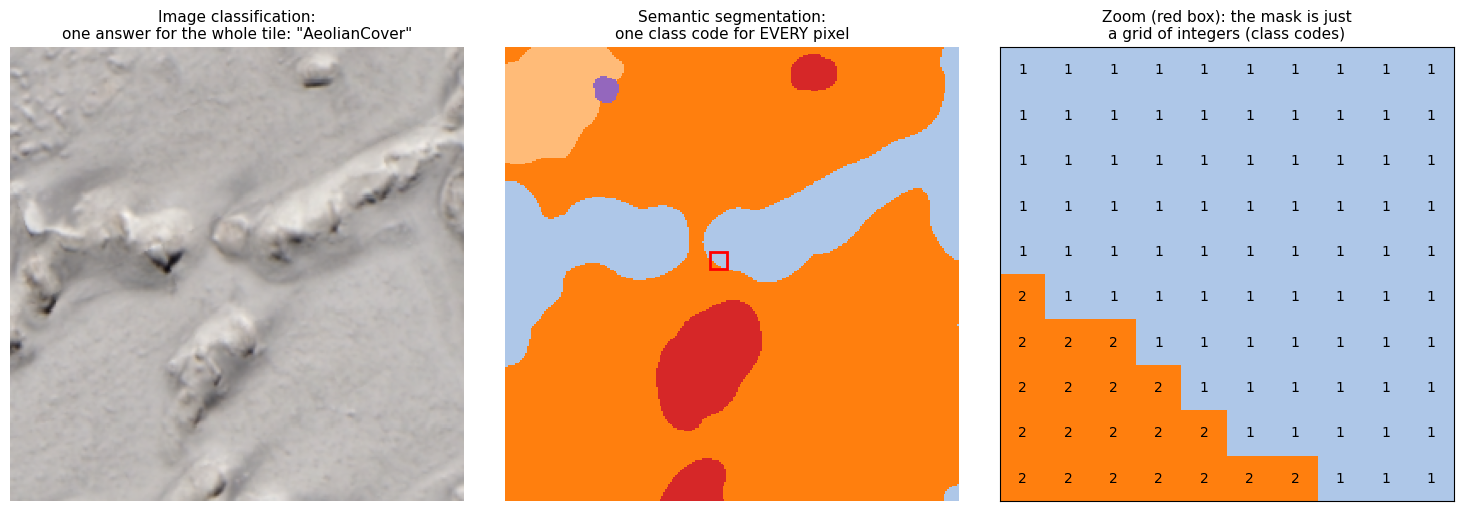

image shape: (267, 267, 3)  (height, width, 3 color channels)
mask shape : (267, 267)       (height, width), one integer per pixel
class codes present in this tile: [1 2 3 6 8]


In [5]:
# Pick one example tile and its label mask
ex_img  = np.asarray(Image.open(f'{DATA_DIR}/ImageData/6cm/Vis/6p9cmVis105.png').convert('RGB'))
ex_mask = np.asarray(Image.open(f'{DATA_DIR}/LabelData/6cm/Vis/6p9cmVisLabel105.png'))

values, counts = np.unique(ex_mask, return_counts=True)
majority = values[counts.argmax()]
names_12 = ['BorderPixels', 'PolygonRidge', 'AeolianCover', 'MottledGround', 'Road', 'ErodedRidgesAndTumuli',
            'Tumulus', 'Objects', 'PatternedGround', 'DrainageChannelRidge', 'MudCrack', 'SaltPan']

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(ex_img); ax[0].axis('off')
ax[0].set_title(f'Image classification:\none answer for the whole tile: "{names_12[majority]}"')

ax[1].imshow(ex_mask, cmap='tab20', vmin=0, vmax=19, interpolation='nearest'); ax[1].axis('off')
ax[1].set_title('Semantic segmentation:\none class code for EVERY pixel')
r0, c0, n = 120, 120, 10          # a 10x10 pixel window to zoom into
ax[1].add_patch(plt.Rectangle((c0, r0), n, n, fill=False, ec='red', lw=2))

patch = ex_mask[r0:r0+n, c0:c0+n]
ax[2].imshow(patch, cmap='tab20', vmin=0, vmax=19)
for (i, j), v in np.ndenumerate(patch):
    ax[2].text(j, i, int(v), ha='center', va='center', fontsize=10, color='black')
ax[2].set_title('Zoom (red box): the mask is just\na grid of integers (class codes)')
ax[2].set_xticks([]); ax[2].set_yticks([])
plt.tight_layout(); plt.show()

print('image shape:', ex_img.shape, ' (height, width, 3 color channels)')
print('mask shape :', ex_mask.shape, '      (height, width), one integer per pixel')
print('class codes present in this tile:', values)

---
## Step 1b: Meet the data, Salar de Pajonales (Atacama Desert, Chile)

Salar de Pajonales is a high-altitude salt flat used as a **Mars analog**: an arid, high-UV, evaporite-rich environment similar to the ancient salt deposits seen on Mars. Researchers mapped it with **drone imagery** and hand-labeled the terrain types to study where microbial life tends to occur, and whether such patterns could be predicted from orbit-like images.

* **Images**: drone visible (RGB) image tiles, 267 × 267 pixels, at about **6.9 cm per pixel** (the `6p9cm` in the file names).
* **Labels**: matching masks with 12 terrain classes drawn by experts.
* **Source**: Zenodo record [10.5281/zenodo.7384288](https://zenodo.org/records/7384288). See Warren-Rhodes, Phillips et al. (2023, *Nature Astronomy*) for the science context.

Every image `6p9cmVis{N}.png` has a mask `6p9cmVisLabel{N}.png` with the same number `N`.

In [6]:
image_files = glob.glob(f'{DATA_DIR}/ImageData/6cm/Vis/*.png')
tile_id = lambda path: int(re.findall(r'(\d+)\.png$', path)[0])   # '.../6p9cmVis105.png' -> 105
image_files = sorted((p.replace(os.sep, '/') for p in image_files), key=tile_id)

def mask_path(img_path):
    # Find the label file that belongs to an image file
    return f'{DATA_DIR}/LabelData/6cm/Vis/6p9cmVisLabel{tile_id(img_path)}.png'

print(f'Number of image tiles: {len(image_files)}')
print('Example pair:\n ', image_files[0], '\n ', mask_path(image_files[0]))

Number of image tiles: 8496
Example pair:
  data/seg-data/ImageData/6cm/Vis/6p9cmVis1.png 
  data/seg-data/LabelData/6cm/Vis/6p9cmVisLabel1.png


The 12 original classes (the integer code stored in the mask is the position in this list):

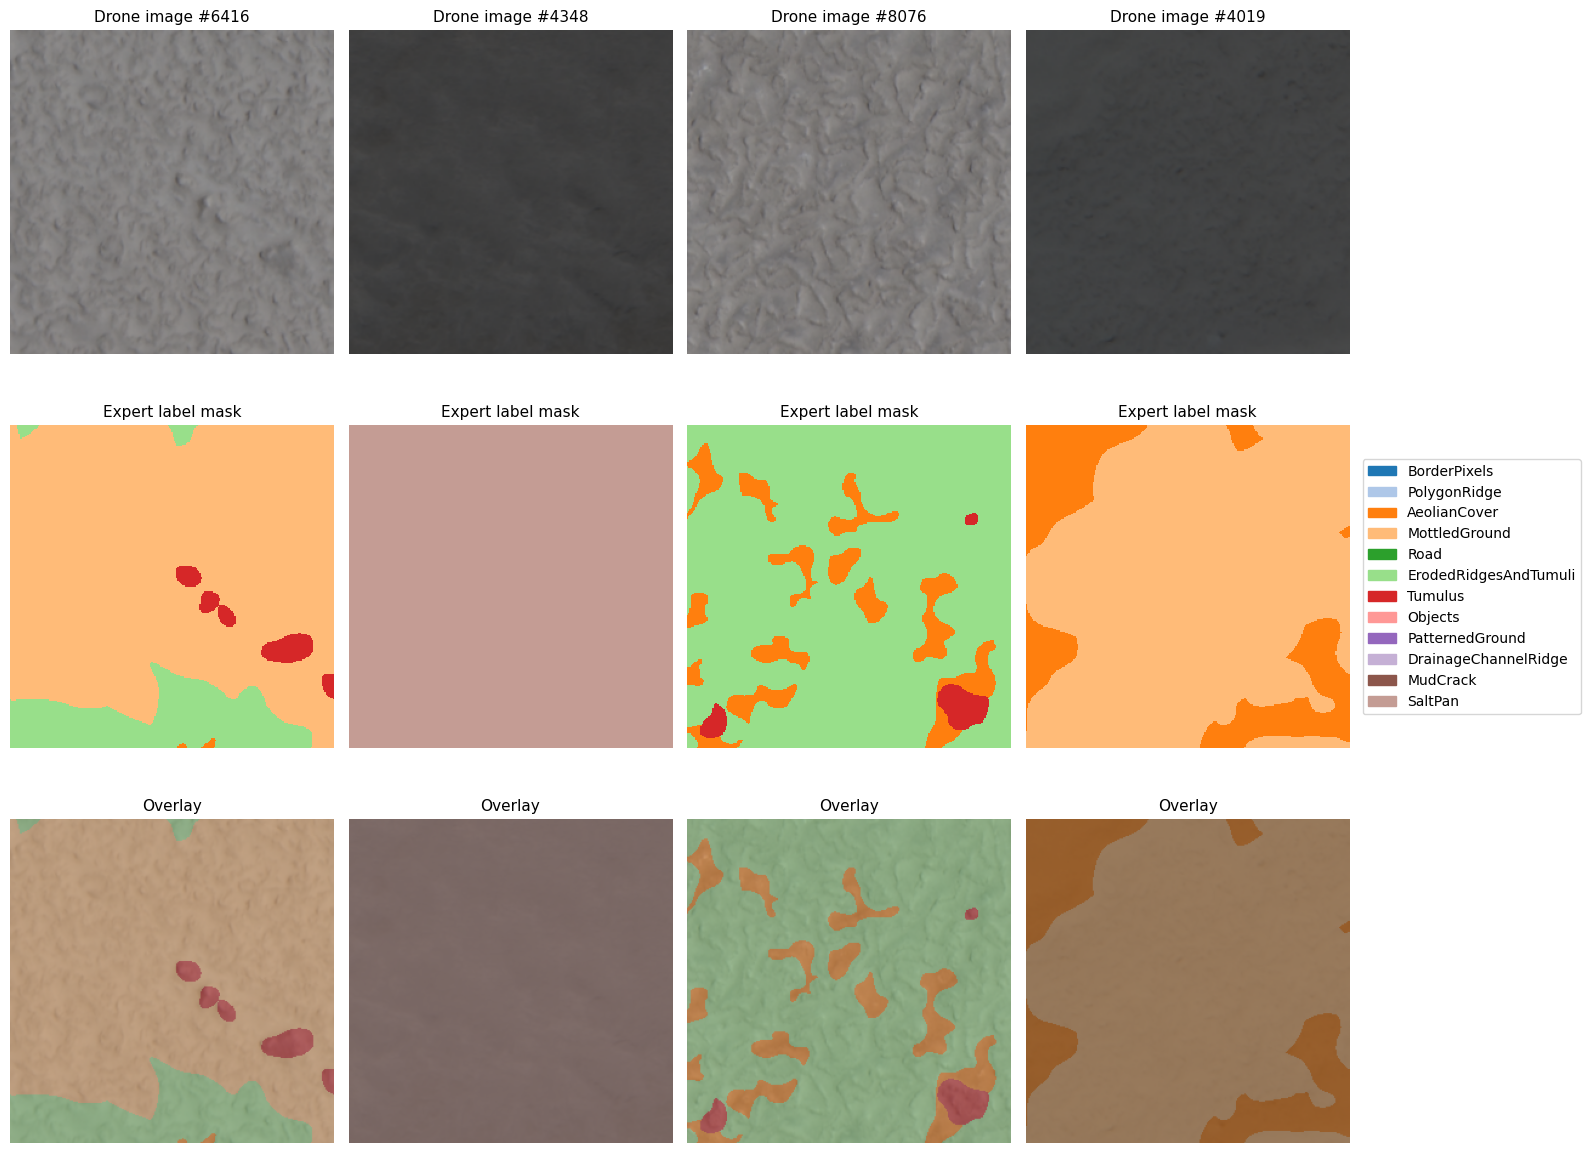

In [7]:
ORIG_CLASSES = ['BorderPixels', 'PolygonRidge', 'AeolianCover', 'MottledGround',
                'Road', 'ErodedRidgesAndTumuli', 'Tumulus', 'Objects',
                'PatternedGround', 'DrainageChannelRidge', 'MudCrack', 'SaltPan']
ORIG_CMAP = ListedColormap(plt.cm.tab20(np.arange(12)))

def show_legend(ax, names, colors, **kw):
    ax.legend(handles=[Patch(color=c, label=n) for n, c in zip(names, colors)], **kw)

def overlay(img, mask_rgb, alpha=0.45):
    # Blend an RGB image (0-255 or 0-1) with a colored mask (0-1)
    img = img / 255.0 if img.max() > 1 else img
    return (1 - alpha) * img + alpha * mask_rgb

rng = np.random.default_rng(1)
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
for col, path in enumerate(rng.choice(image_files, 4, replace=False)):
    img = np.asarray(Image.open(path).convert('RGB'))
    m   = np.asarray(Image.open(mask_path(path)))
    ax[0, col].imshow(img);                                         ax[0, col].set_title(f'Drone image #{tile_id(path)}')
    ax[1, col].imshow(m, cmap=ORIG_CMAP, vmin=-0.5, vmax=11.5, interpolation='nearest'); ax[1, col].set_title('Expert label mask')
    ax[2, col].imshow(overlay(img, ORIG_CMAP(m)[..., :3]));         ax[2, col].set_title('Overlay')
for a in ax.ravel(): a.axis('off')
show_legend(ax[1, 3], ORIG_CLASSES, ORIG_CMAP.colors, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10)
plt.tight_layout(); plt.show()

---
## Step 2: Simplify the labels (12 classes → 4 terrain units)

Some classes are extremely rare (e.g. *Objects* < 0.1 % of pixels) or are not geology (*Road*, *BorderPixels*). For this lab, we group the classes into **4 broad terrain units**, a common first step in real mapping projects:

| New class | Built from original classes | Geologic meaning |
|---|---|---|
| **0 Aeolian cover** | AeolianCover | wind-blown sediment veneer |
| **1 Mottled ground** | MottledGround | patchy, mixed-tone surface |
| **2 Ridges & tumuli** | PolygonRidge, ErodedRidgesAndTumuli, Tumulus | raised gypsum ridges and domes |
| **3 Salt pan** | SaltPan | flat evaporite crust |
| *ignored* | BorderPixels, Road, Objects, PatternedGround, DrainageChannelRidge, MudCrack | everything else, about 4 % of pixels |

**Ignored pixels** get the special code `255`. The model makes predictions there, but we **don't grade it** on them, neither during training (the loss) nor during evaluation. This is the standard way to handle "unlabeled" or "don't care" regions.

The remapping is done with a **look-up table (LUT)**: `new_mask = LUT[old_mask]`.

In [8]:
IGNORE = 255
CLASSES = ['Aeolian cover', 'Mottled ground', 'Ridges & tumuli', 'Salt pan']
NUM_CLASSES = len(CLASSES)
COLORS = np.array([[0.90, 0.62, 0.00],    # orange  - Aeolian cover
                   [0.34, 0.71, 0.91],    # sky blue - Mottled ground
                   [0.80, 0.47, 0.65],    # pink    - Ridges & tumuli
                   [0.00, 0.62, 0.45]])   # green   - Salt pan

#            orig code:  0       1  2  3  4       5  6  7       8       9       10      11
LUT = np.array([IGNORE, 2, 0, 1, IGNORE, 2, 2, IGNORE, IGNORE, IGNORE, IGNORE, 3], dtype=np.uint8)
for old, new in enumerate(LUT):
    print(f'{ORIG_CLASSES[old]:>22s} ({old:2d})  ->  {CLASSES[new] if new != IGNORE else "ignored (255)"}')

def colorize(mask):
    # Turn a mask of class codes into an RGB picture (ignored pixels -> black)
    rgb = np.zeros(mask.shape + (3,))
    for c in range(NUM_CLASSES):
        rgb[mask == c] = COLORS[c]
    return rgb

          BorderPixels ( 0)  ->  ignored (255)
          PolygonRidge ( 1)  ->  Ridges & tumuli
          AeolianCover ( 2)  ->  Aeolian cover
         MottledGround ( 3)  ->  Mottled ground
                  Road ( 4)  ->  ignored (255)
 ErodedRidgesAndTumuli ( 5)  ->  Ridges & tumuli
               Tumulus ( 6)  ->  Ridges & tumuli
               Objects ( 7)  ->  ignored (255)
       PatternedGround ( 8)  ->  ignored (255)
  DrainageChannelRidge ( 9)  ->  ignored (255)
              MudCrack (10)  ->  ignored (255)
               SaltPan (11)  ->  Salt pan


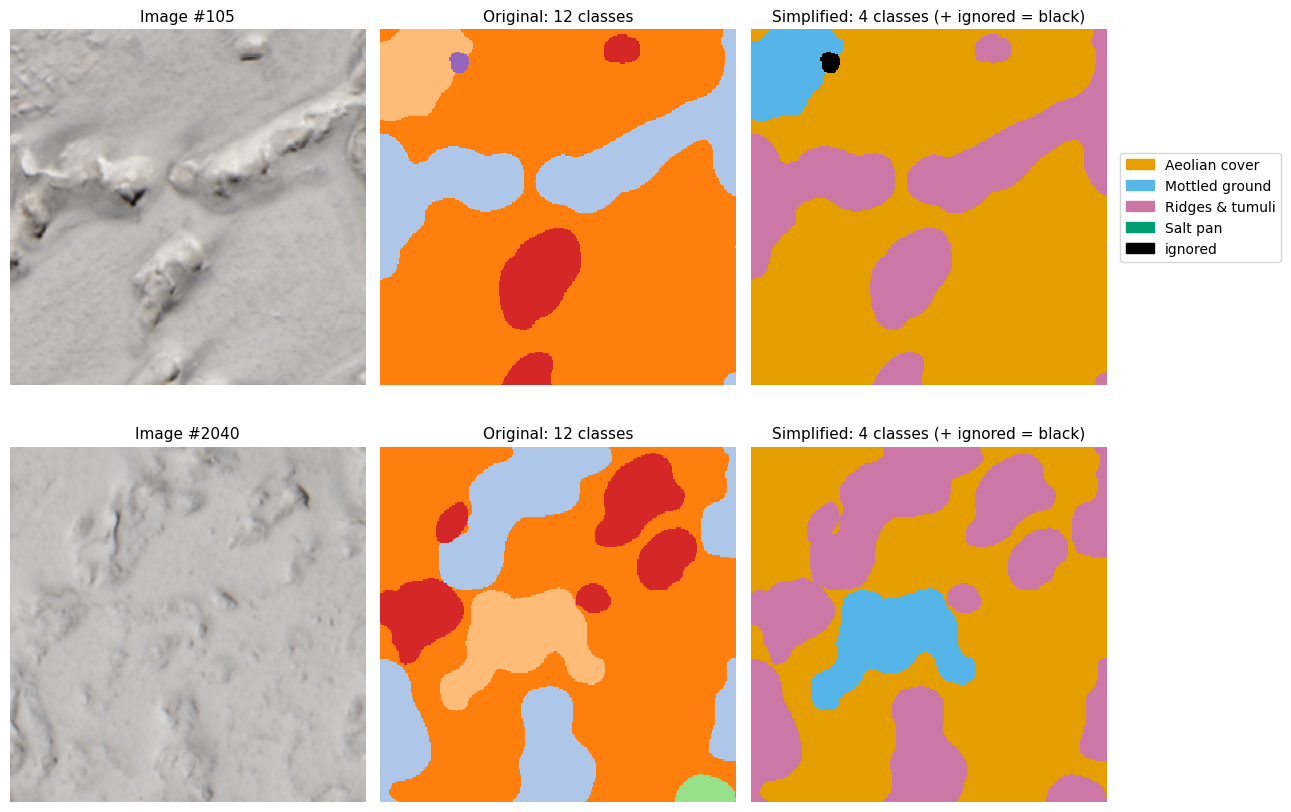

In [9]:
# Before / after for two tiles
fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
for row, n in enumerate([105, 2040]):
    img = np.asarray(Image.open(f'{DATA_DIR}/ImageData/6cm/Vis/6p9cmVis{n}.png').convert('RGB'))
    m12 = np.asarray(Image.open(f'{DATA_DIR}/LabelData/6cm/Vis/6p9cmVisLabel{n}.png'))
    ax[row, 0].imshow(img); ax[row, 0].set_title(f'Image #{n}')
    ax[row, 1].imshow(m12, cmap=ORIG_CMAP, vmin=-0.5, vmax=11.5, interpolation='nearest'); ax[row, 1].set_title('Original: 12 classes')
    ax[row, 2].imshow(colorize(LUT[m12]), interpolation='nearest'); ax[row, 2].set_title('Simplified: 4 classes (+ ignored = black)')
for a in ax.ravel(): a.axis('off')
show_legend(ax[0, 2], CLASSES + ['ignored'], list(COLORS) + ['black'], loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout(); plt.show()

---
## Step 3: Build the data pipeline

### 3a. Load a subset and resize
We load `N_TILES` random tiles and shrink them to `IMG_SIZE × IMG_SIZE`.

⚠️ **Images and masks must be resized differently.**
* Images use **bilinear** interpolation (smooth blending of neighboring pixels is fine for brightness).
* Masks must use **nearest-neighbor**. Blending class codes makes no sense: halfway between "Aeolian (0)" and "Ridges (2)" is *not* "Mottled (1)"!

In [10]:
# Quick demonstration of why masks need nearest-neighbor resizing
m = Image.open(f'{DATA_DIR}/LabelData/6cm/Vis/6p9cmVisLabel105.png')
print('codes after NEAREST  resize:', np.unique(np.asarray(m.resize((64, 64), Image.NEAREST))))
print('codes after BILINEAR resize:', np.unique(np.asarray(m.resize((64, 64), Image.BILINEAR))), ' <- invented codes!')

codes after NEAREST  resize: [1 2 3 6 8]
codes after BILINEAR resize: [1 2 3 4 5 6 7 8]  <- invented codes!


In [11]:
def load_tiles(paths, size):
    imgs, masks = [], []
    for p in paths:
        img = Image.open(p).convert('RGB').resize((size, size), Image.BILINEAR)
        msk = Image.open(mask_path(p)).resize((size, size), Image.NEAREST)
        imgs.append(np.asarray(img))
        masks.append(LUT[np.asarray(msk)])            # remap 12 -> 4 classes here
    return np.stack(imgs), np.stack(masks)

t0 = time.time()
chosen = np.random.default_rng(SEED).choice(image_files, N_TILES, replace=False)
images, masks = load_tiles(chosen, IMG_SIZE)
print(f'Loaded {len(images)} tiles in {time.time() - t0:.1f} s')
print('images:', images.shape, images.dtype, '| masks:', masks.shape, masks.dtype)

Loaded 3000 tiles in 8.0 s
images: (3000, 128, 128, 3) uint8 | masks: (3000, 128, 128) uint8


### 3b. Split into training / validation / test sets
* **Training (70 %)**: the model learns from these.
* **Validation (15 %)**: checked after every epoch to monitor progress and pick the best model.
* **Test (15 %)**: kept locked away until the very end, for an honest final score.



In [12]:
idx = np.random.default_rng(SEED).permutation(N_TILES)
n_tr, n_va = int(0.70 * N_TILES), int(0.15 * N_TILES)
tr_idx, va_idx, te_idx = idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:]
X_train, y_train = images[tr_idx], masks[tr_idx]
X_val,   y_val   = images[va_idx], masks[va_idx]
X_test,  y_test  = images[te_idx], masks[te_idx]
print(f'train: {len(X_train)}   val: {len(X_val)}   test: {len(X_test)}')

train: 2100   val: 450   test: 450


### 3c. How balanced are the classes?
If one class covers most pixels, a lazy model could score well by always predicting it. We counter that with **class weights**: rare classes count more in the loss. (We use the square root of the "inverse frequency" weight, a gentle version that keeps training stable.)

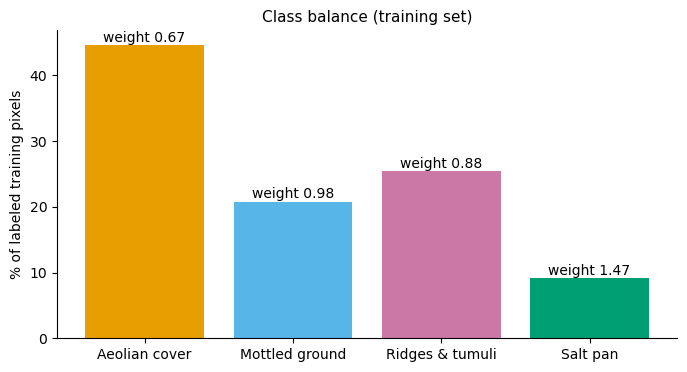

Ignored pixels: 4.2 % of the training set


In [13]:
counts = np.array([(y_train == c).sum() for c in range(NUM_CLASSES)])
freq = counts / counts.sum()
class_weights = np.sqrt(1.0 / (NUM_CLASSES * freq))
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(CLASSES, 100 * freq, color=COLORS)
for b, w in zip(bars, class_weights):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f'weight {w:.2f}', ha='center')
ax.set_ylabel('% of labeled training pixels'); ax.set_title('Class balance (training set)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()
print(f'Ignored pixels: {100 * (y_train == IGNORE).mean():.1f} % of the training set')

### 3d. Normalize, augment, and wrap in a PyTorch `Dataset`

**Normalization.** Networks train best when inputs are centered around 0 with a spread of about 1. We subtract the mean and divide by the standard deviation of each color channel (computed on the *training* set only).

**Data augmentation.** A drone looking straight down has no preferred "up". A ridge rotated by 90° is still a ridge. We randomly **rotate (0/90/180/270°) and mirror** each training tile, which gives the model "new" examples for free.
The **image and its mask must be transformed identically**, or the labels would no longer line up with the terrain.

**PyTorch layout.** PyTorch stores images as `(channels, height, width)`, and a batch as `(batch, channels, height, width)`.

In [14]:
MEAN = X_train.reshape(-1, 3).mean(0) / 255.0
STD  = X_train.reshape(-1, 3).std(0)  / 255.0
print('channel mean:', MEAN.round(3), ' channel std:', STD.round(3))

class SegDataset(Dataset):
    # Serves (image, mask) pairs as PyTorch tensors, optionally augmented
    def __init__(self, images, masks, augment=False):
        self.images, self.masks, self.augment = images, masks, augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = (self.images[i] / 255.0 - MEAN) / STD           # normalize, shape (H, W, 3)
        img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)   # -> (3, H, W)
        msk = torch.tensor(self.masks[i], dtype=torch.long)             # -> (H, W)
        if self.augment:
            k = np.random.randint(4)                                    # same random rotation...
            img, msk = torch.rot90(img, k, (1, 2)), torch.rot90(msk, k, (0, 1))
            if np.random.rand() < 0.5:                                  # ...and same mirror for both
                img, msk = img.flip(2), msk.flip(1)
        return img, msk

def to_display(img_tensor):
    # Undo the normalization so a tensor can be shown as a picture
    img = img_tensor.cpu().permute(1, 2, 0).numpy() * STD + MEAN
    return np.clip(img, 0, 1)

train_ds = SegDataset(X_train, y_train, augment=True)
val_ds   = SegDataset(X_val,   y_val)
test_ds  = SegDataset(X_test,  y_test)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)
test_loader  = DataLoader(test_ds,  batch_size=64)

xb, yb = next(iter(train_loader))
print('one batch of images:', tuple(xb.shape), '-> (batch, channels, height, width)')
print('one batch of masks :', tuple(yb.shape), '     -> (batch, height, width)')

channel mean: [0.497 0.491 0.489]  channel std: [0.208 0.205 0.205]
one batch of images: (16, 3, 128, 128) -> (batch, channels, height, width)
one batch of masks : (16, 128, 128)      -> (batch, height, width)


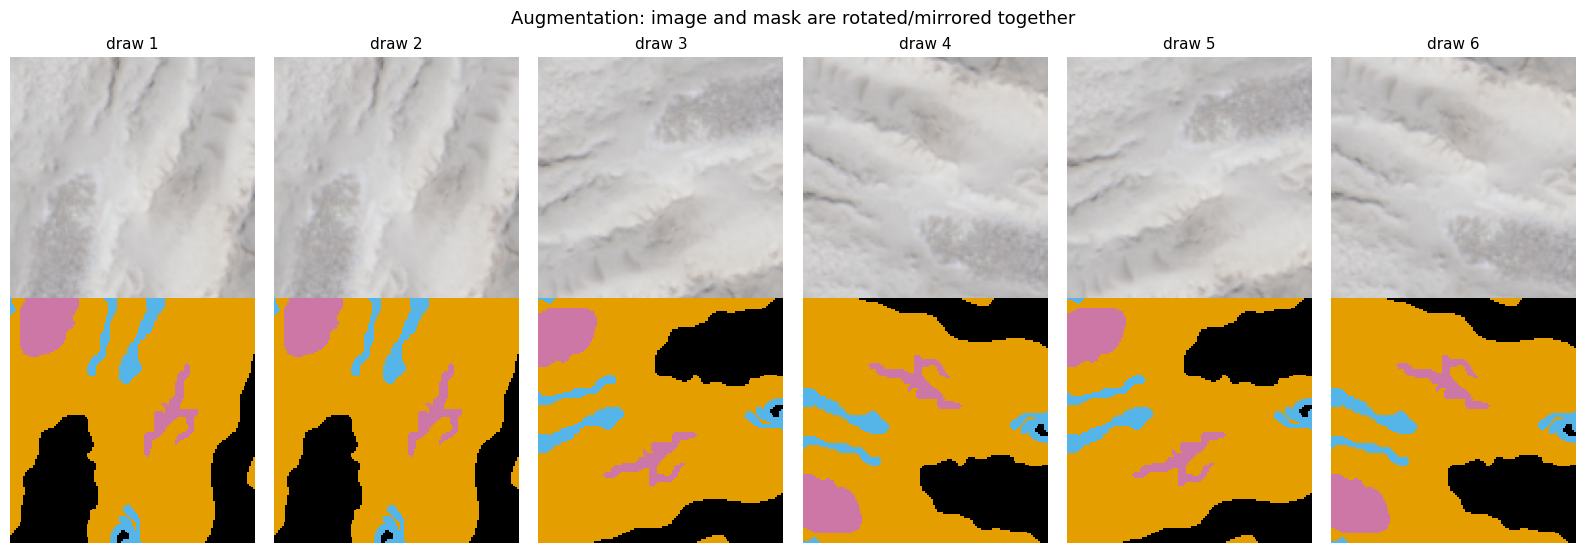

In [15]:
# See augmentation in action: the SAME tile, drawn 6 times from the training dataset
fig, ax = plt.subplots(2, 6, figsize=(16, 5.6))
for j in range(6):
    img, msk = train_ds[0]
    ax[0, j].imshow(to_display(img)); ax[1, j].imshow(colorize(msk.numpy()), interpolation='nearest')
    ax[0, j].set_title(f'draw {j + 1}')
for a in ax.ravel(): a.axis('off')
ax[0, 0].set_ylabel('image'); fig.suptitle('Augmentation: image and mask are rotated/mirrored together', fontsize=13)
plt.tight_layout(); plt.show()

---
## Step 4: Build a U-Net

<center><img src="../files/unet_architecture.png" alt="U-Net architecture" width="700"></center>

The U-Net ([Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597)) has three parts:

1. **Encoder (left side, going down).** Repeated *convolution → convolution → max-pool*. Each level halves the image size and doubles the number of feature channels. Early levels detect **edges and textures**; deeper levels see larger areas and capture **context** ("this is a field of polygonal ridges").
2. **Decoder (right side, going up).** *Transposed convolutions* double the size again, step by step, back to the full resolution.
3. **Skip connections (grey arrows).** The decoder at each level is handed the encoder's feature maps from the same level. Deep layers know *what* is there but have lost *exactly where*; skip connections restore the fine spatial detail, so boundaries come out sharp.

### What changes compared with the autoencoder notebook?
| | Autoencoder (Notebook 2) | Segmentation U-Net (this lab) |
|---|---|---|
| Target | the input image itself | the label mask |
| Bottleneck | squeezed to a 16-number latent vector | stays a (small) image of features |
| Skip connections | **none**: everything must pass through the bottleneck | **yes**: fine detail bypasses the bottleneck for sharp boundaries |
| Final layer | 1 channel: brightness | **4 channels: one score per class**, per pixel |
| Loss | pixel error (+ roughness) | **cross-entropy** (classification at every pixel) |

In the autoencoder, skip connections would have let the network "cheat" around the bottleneck. Here we *want* that shortcut, because our goal is a sharp map, not a compact code.

The final **1×1 convolution** turns the features at each pixel into 4 numbers called **logits** (one score per class). *Softmax* turns them into probabilities, and *argmax* picks the most likely class, giving us the map.

We also add **Batch Normalization** after each convolution, which makes training faster and more stable.

In [16]:
def conv_block(in_ch, out_ch):
    # Two 3x3 convolutions, each followed by BatchNorm and ReLU (image size unchanged)
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
    )

class EncoderBlock(nn.Module):
    # conv_block, then max-pool: returns (features for the skip connection, downsampled features)
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = conv_block(in_ch, out_ch)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        skip = self.conv(x)
        return skip, self.pool(skip)

class DecoderBlock(nn.Module):
    # Upsample x2, glue on the skip features (concatenate channels), then conv_block
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = conv_block(2 * out_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=4, filters=(16, 32, 64, 128)):
        super().__init__()
        self.encoders = nn.ModuleList()
        ch = in_ch
        for f in filters:                                   # going down: 3 -> 16 -> 32 -> 64 -> 128
            self.encoders.append(EncoderBlock(ch, f)); ch = f
        self.bottleneck = conv_block(ch, 2 * ch); ch = 2 * ch   # bottom of the "U": 256 channels
        self.decoders = nn.ModuleList()
        for f in reversed(filters):                         # going up: 256 -> 128 -> 64 -> 32 -> 16
            self.decoders.append(DecoderBlock(ch, f)); ch = f
        self.head = nn.Conv2d(ch, num_classes, kernel_size=1)   # 16 features -> 4 class scores per pixel

    def forward(self, x, return_features=False):
        feats, skips = {'input': x}, []
        for i, enc in enumerate(self.encoders):
            skip, x = enc(x)
            skips.append(skip); feats[f'encoder {i + 1}'] = skip
        x = self.bottleneck(x); feats['bottleneck'] = x
        for i, (dec, skip) in enumerate(zip(self.decoders, reversed(skips))):
            x = dec(x, skip); feats[f'decoder {len(skips) - i}'] = x
        logits = self.head(x); feats['output (logits)'] = logits
        return (logits, feats) if return_features else logits

model = UNet(num_classes=NUM_CLASSES).to(device)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

Trainable parameters: 1,942,628


### Follow one batch through the network
Watch the shape change at every stage: **spatial size goes down then back up, channels go up then back down**. That is the "U".

In [17]:
with torch.no_grad():
    _, feats = model(xb[:1].to(device), return_features=True)

print(f'{"stage":<18}{"shape (batch, channels, H, W)":<32}{"pixel size on the ground"}')
print('-' * 76)
for name, f in feats.items():
    gsd = 0.069 * 267 / f.shape[-1]     # original tile: 267 px x 6.9 cm; metres per (feature) pixel
    print(f'{name:<18}{str(tuple(f.shape)):<32}{gsd * 100:6.0f} cm')

stage             shape (batch, channels, H, W)   pixel size on the ground
----------------------------------------------------------------------------
input             (1, 3, 128, 128)                    14 cm
encoder 1         (1, 16, 128, 128)                   14 cm
encoder 2         (1, 32, 64, 64)                     29 cm
encoder 3         (1, 64, 32, 32)                     58 cm
encoder 4         (1, 128, 16, 16)                   115 cm
bottleneck        (1, 256, 8, 8)                     230 cm
decoder 4         (1, 128, 16, 16)                   115 cm
decoder 3         (1, 64, 32, 32)                     58 cm
decoder 2         (1, 32, 64, 64)                     29 cm
decoder 1         (1, 16, 128, 128)                   14 cm
output (logits)   (1, 4, 128, 128)                    14 cm


### The untrained network is just guessing
Before training, the weights are random. Here is what it predicts. Each class gets a "probability map", and the final map takes the highest one at each pixel. Notice every probability is close to **0.25 = 1/4**: the network has no idea yet and spreads its bets evenly over the 4 classes.

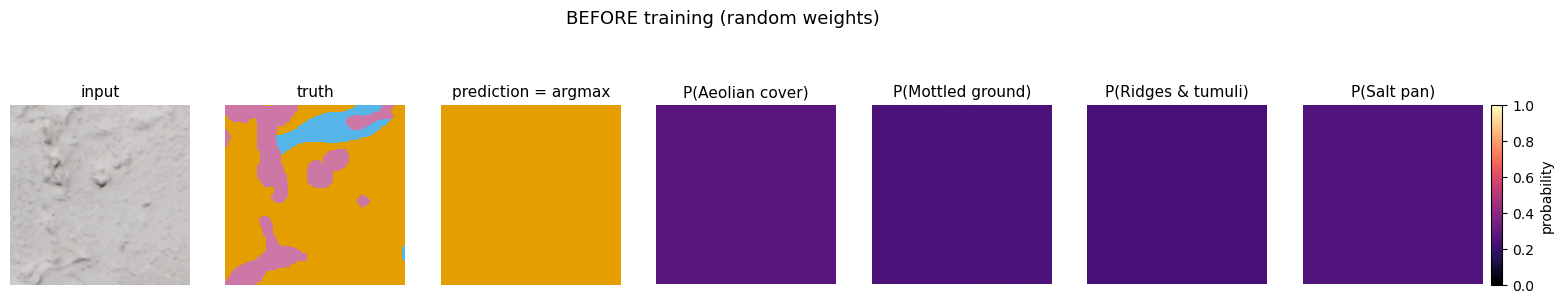

In [18]:
def predict(model, x):
    # Return class probabilities (B, C, H, W) for a batch of normalized images
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(x.to(device)), dim=1).cpu()

def show_probabilities(model, img, msk, title):
    prob = predict(model, img[None])[0]
    fig, ax = plt.subplots(1, 3 + NUM_CLASSES, figsize=(19, 3.4))
    ax[0].imshow(to_display(img)); ax[0].set_title('input')
    ax[1].imshow(colorize(msk.numpy()), interpolation='nearest'); ax[1].set_title('truth')
    ax[2].imshow(colorize(prob.argmax(0).numpy()), interpolation='nearest'); ax[2].set_title('prediction = argmax')
    for c in range(NUM_CLASSES):
        im = ax[3 + c].imshow(prob[c], vmin=0, vmax=1, cmap='magma'); ax[3 + c].set_title(f'P({CLASSES[c]})')
    for a in ax: a.axis('off')
    fig.colorbar(im, cax=ax[-1].inset_axes([1.05, 0, 0.06, 1]), label='probability')
    fig.suptitle(title, fontsize=13, y=1.04); plt.show()

show_probabilities(model, *val_ds[3], 'BEFORE training (random weights)')

---
## Step 5: Train the network

### The loss: cross-entropy at every pixel
At every pixel, the network outputs probabilities for the 4 classes. **Cross-entropy** is small when the probability of the *true* class is high, and large when the network is confidently wrong: `loss = −log(p_true)`. We average it over all (non-ignored) pixels, weighting rare classes more.

### Metrics: how good is the map?
* **Pixel accuracy**: fraction of pixels labeled correctly. Easy to understand, but inflated by common classes.
* **IoU (Intersection over Union)** for one class: overlap between predicted and true regions divided by their combined area. 1 = perfect, 0 = no overlap. **mIoU** is the mean IoU over classes, the standard segmentation score.

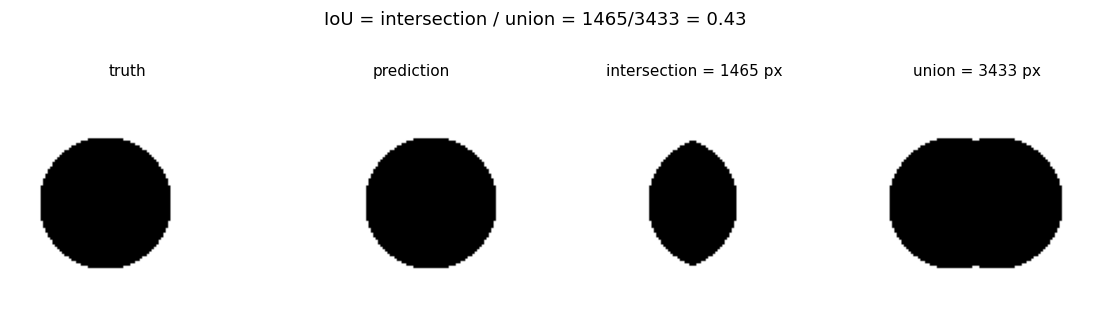

In [19]:
# A toy example of IoU: two overlapping "regions"
yy, xx = np.mgrid[:100, :100]
truth_toy = (xx - 40) ** 2 + (yy - 50) ** 2 < 28 ** 2
pred_toy  = (xx - 58) ** 2 + (yy - 50) ** 2 < 28 ** 2
inter, union = (truth_toy & pred_toy).sum(), (truth_toy | pred_toy).sum()

fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, img, t in zip(ax, [truth_toy, pred_toy, truth_toy & pred_toy, truth_toy | pred_toy],
                     ['truth', 'prediction', f'intersection = {inter} px', f'union = {union} px']):
    a.imshow(img, cmap='Greys'); a.set_title(t); a.axis('off')
fig.suptitle(f'IoU = intersection / union = {inter}/{union} = {inter / union:.2f}', fontsize=13, y=1.03)
plt.show()

In [20]:
def confusion_matrix(pred, true, n=NUM_CLASSES):
    # Rows = true class, columns = predicted class; ignored pixels are skipped
    keep = true != IGNORE
    return torch.bincount(n * true[keep] + pred[keep], minlength=n * n).reshape(n, n)

def scores(cm):
    cm = cm.double()
    tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    return {'acc': (tp.sum() / cm.sum()).item(), 'miou': iou.mean().item(), 'iou': iou.numpy()}

def evaluate(model, loader, loss_fn):
    model.eval()
    cm, total_loss = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long), 0.0
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            total_loss += loss_fn(logits, y.to(device)).item() * len(x)
            cm += confusion_matrix(logits.argmax(1).cpu(), y)
    return total_loss / len(loader.dataset), scores(cm), cm

def train(model, epochs, lr, save_path, snapshot_tiles=None):
    # Standard PyTorch training loop. Returns the history of losses/metrics
    loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device), ignore_index=IGNORE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    # "One-cycle" schedule: learning rate warms up, then decays smoothly to ~0
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=epochs * len(train_loader))
    history = {k: [] for k in ['loss', 'val_loss', 'acc', 'val_acc', 'val_miou', 'snapshots']}
    best = -1
    for epoch in range(1, epochs + 1):
        t0 = time.time(); model.train()
        cm, run_loss = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long), 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)                    # 1. forward pass: make predictions
            loss = loss_fn(logits, y)            # 2. how wrong are they?
            optimizer.zero_grad()
            loss.backward()                      # 3. backpropagation: compute gradients
            optimizer.step()                     # 4. nudge the weights downhill
            scheduler.step()
            run_loss += loss.item() * len(x)
            cm += confusion_matrix(logits.argmax(1).cpu(), y.cpu())
        val_loss, val, _ = evaluate(model, val_loader, loss_fn)
        history['loss'].append(run_loss / len(train_loader.dataset)); history['acc'].append(scores(cm)['acc'])
        history['val_loss'].append(val_loss); history['val_acc'].append(val['acc']); history['val_miou'].append(val['miou'])
        if snapshot_tiles is not None:           # remember predictions on a few fixed tiles
            history['snapshots'].append(predict(model, snapshot_tiles).argmax(1))
        flag = ''
        if val['miou'] > best:                   # keep the best model (by validation mIoU)
            best = val['miou']; torch.save(model.state_dict(), save_path); flag = '  <- best so far, saved'
        print(f'epoch {epoch:2d}/{epochs} | train loss {history["loss"][-1]:.3f} acc {history["acc"][-1]:.3f} '
              f'| val loss {val_loss:.3f} acc {val["acc"]:.3f} mIoU {val["miou"]:.3f} | {time.time() - t0:4.1f}s{flag}')
    return history

### Run training
Each line below is one **epoch** (one full pass through the training tiles). Watch the **validation** numbers: that is how the model does on tiles it has *not* trained on.

We also record the model's predictions on 4 fixed validation tiles after every epoch, so we can watch the map improve.

In [21]:
snap_ids = [3, 10, 25, 40]
snap_x = torch.stack([val_ds[i][0] for i in snap_ids])

torch.manual_seed(SEED)
model = UNet(num_classes=NUM_CLASSES).to(device)
UNET_PATH = f'{MODEL_DIR}/unet_seg.pt'
history = train(model, EPOCHS, LR, UNET_PATH, snapshot_tiles=snap_x)

epoch  1/15 | train loss 1.370 acc 0.274 | val loss 1.277 acc 0.414 mIoU 0.259 | 15.9s  <- best so far, saved
epoch  2/15 | train loss 1.154 acc 0.492 | val loss 1.083 acc 0.565 mIoU 0.341 | 11.7s  <- best so far, saved
epoch  3/15 | train loss 1.125 acc 0.486 | val loss 1.337 acc 0.429 mIoU 0.242 | 11.9s
epoch  4/15 | train loss 1.134 acc 0.479 | val loss 1.258 acc 0.400 mIoU 0.236 | 11.9s
epoch  5/15 | train loss 1.048 acc 0.530 | val loss 1.210 acc 0.383 mIoU 0.200 | 11.6s
epoch  6/15 | train loss 1.016 acc 0.542 | val loss 1.001 acc 0.518 mIoU 0.336 | 11.6s
epoch  7/15 | train loss 0.946 acc 0.586 | val loss 1.107 acc 0.462 mIoU 0.288 | 11.6s
epoch  8/15 | train loss 0.927 acc 0.597 | val loss 1.065 acc 0.496 mIoU 0.321 | 11.6s
epoch  9/15 | train loss 0.880 acc 0.616 | val loss 0.844 acc 0.619 mIoU 0.444 | 11.6s  <- best so far, saved
epoch 10/15 | train loss 0.867 acc 0.626 | val loss 1.026 acc 0.548 mIoU 0.358 | 11.6s
epoch 11/15 | train loss 0.853 acc 0.627 | val loss 0.840 acc

### Learning curves

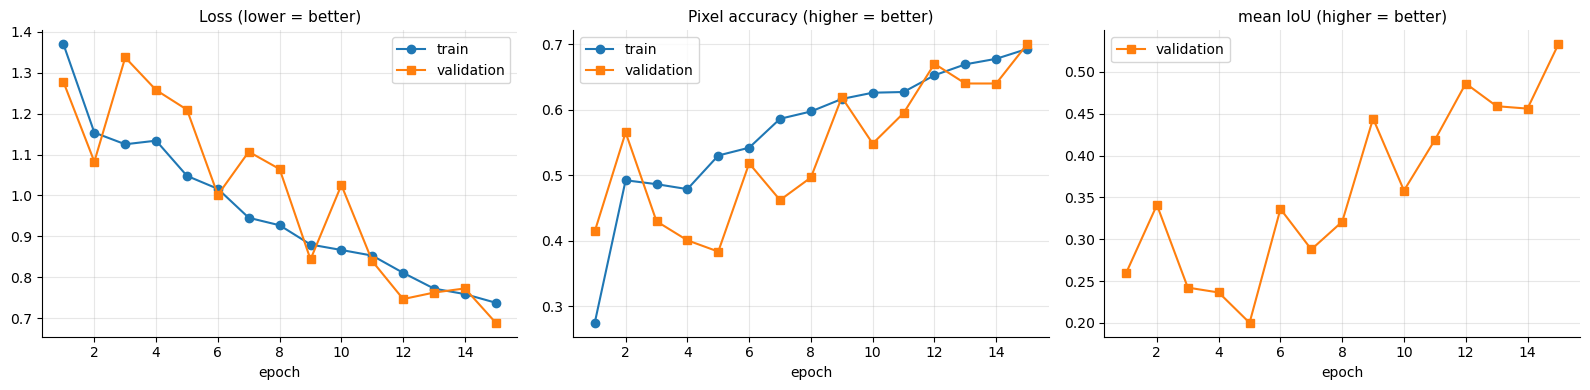

In [22]:
ep = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ep, history['loss'], 'o-', label='train'); ax[0].plot(ep, history['val_loss'], 's-', label='validation')
ax[0].set_title('Loss (lower = better)')
ax[1].plot(ep, history['acc'], 'o-', label='train'); ax[1].plot(ep, history['val_acc'], 's-', label='validation')
ax[1].set_title('Pixel accuracy (higher = better)')
ax[2].plot(ep, history['val_miou'], 's-', color='C1', label='validation'); ax[2].set_title('mean IoU (higher = better)')
for a in ax:
    a.set_xlabel('epoch'); a.legend(); a.grid(alpha=0.3); a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### Watch the network learn
Rows are epochs, columns are the same 4 validation tiles. Early maps are blobby guesses; later ones follow the terrain.

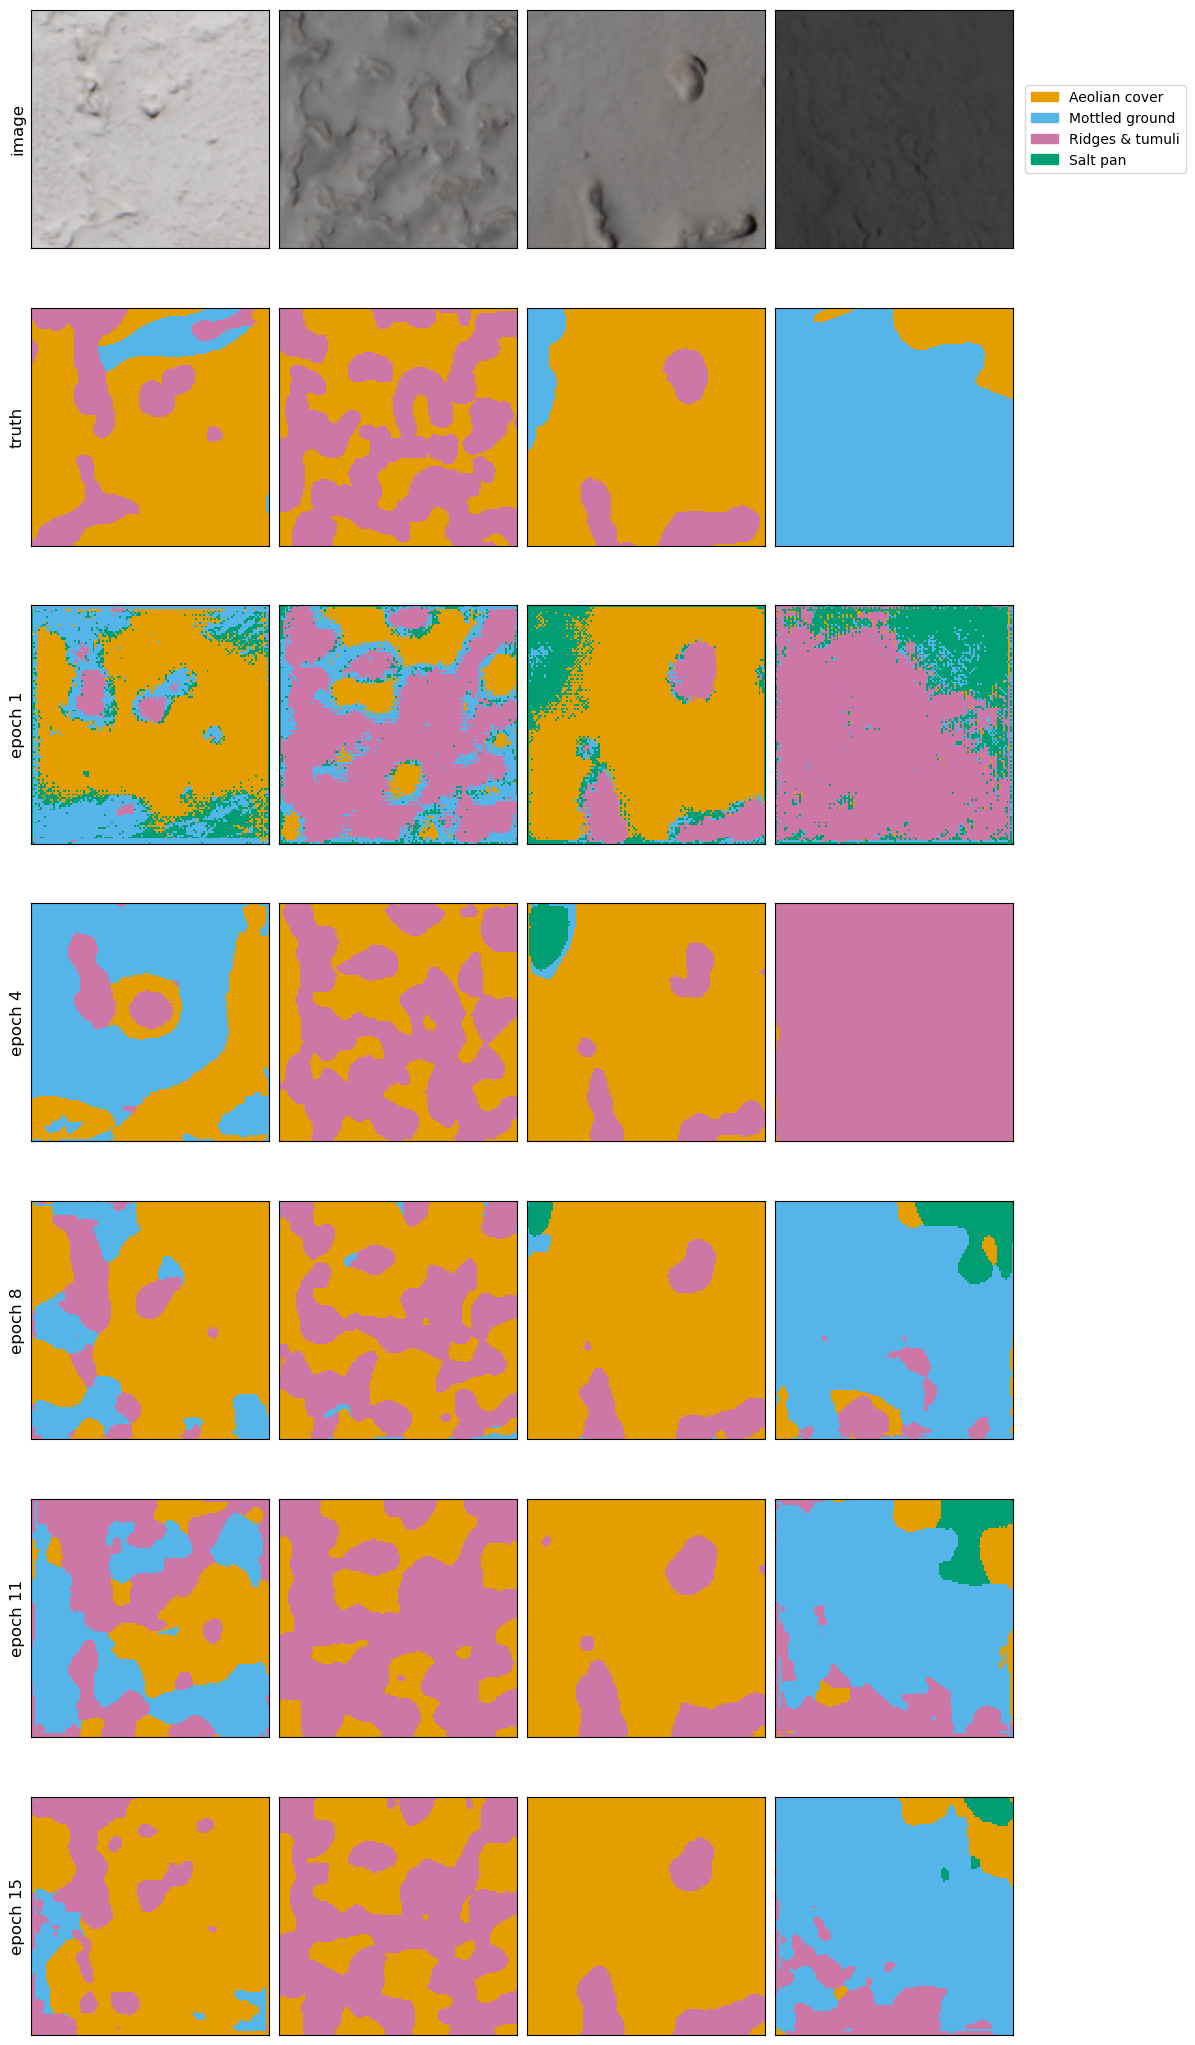

In [23]:
show_epochs = sorted(set(np.linspace(1, EPOCHS, 5).astype(int)))
fig, ax = plt.subplots(len(show_epochs) + 2, len(snap_ids), figsize=(12, 3 * (len(show_epochs) + 2)))
for j, i in enumerate(snap_ids):
    img, msk = val_ds[i]
    ax[0, j].imshow(to_display(img)); ax[1, j].imshow(colorize(msk.numpy()), interpolation='nearest')
    for r, e in enumerate(show_epochs):
        ax[r + 2, j].imshow(colorize(history['snapshots'][e - 1][j].numpy()), interpolation='nearest')
ax[0, 0].set_ylabel('image', fontsize=12); ax[1, 0].set_ylabel('truth', fontsize=12)
for r, e in enumerate(show_epochs):
    ax[r + 2, 0].set_ylabel(f'epoch {e}', fontsize=12)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
show_legend(ax[0, -1], CLASSES, COLORS, loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout(); plt.show()

---
## Step 6: Evaluate on the test set
Now we unlock the **test tiles** and load the best saved model (highest validation mIoU).

TEST pixel accuracy: 0.709
TEST mean IoU      : 0.556
(always guessing the most common class would give accuracy 0.446)



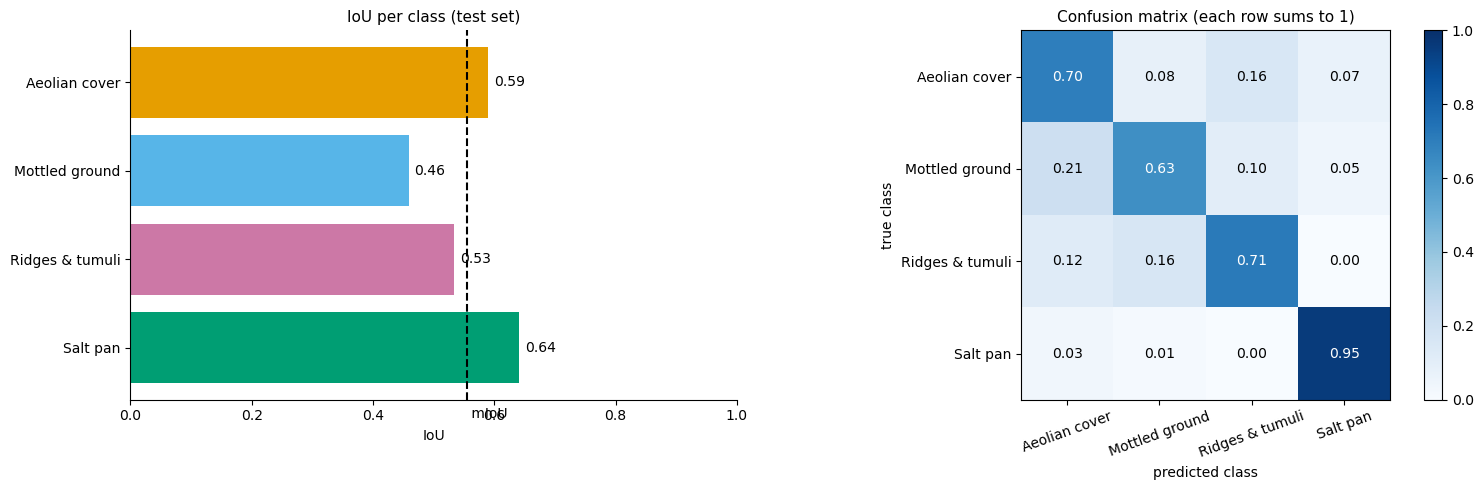

In [24]:
model.load_state_dict(torch.load(UNET_PATH, map_location=device))
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device), ignore_index=IGNORE)
test_loss, test_scores, test_cm = evaluate(model, test_loader, loss_fn)

print(f'TEST pixel accuracy: {test_scores["acc"]:.3f}')
print(f'TEST mean IoU      : {test_scores["miou"]:.3f}')
print(f'(always guessing the most common class would give accuracy {freq.max():.3f})\n')

cm_norm = (test_cm / test_cm.sum(1, keepdim=True)).numpy()
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.1]})
ax[0].barh(CLASSES[::-1], test_scores['iou'][::-1], color=COLORS[::-1])
for k, v in enumerate(test_scores['iou'][::-1]):
    ax[0].text(v + 0.01, k, f'{v:.2f}', va='center')
ax[0].axvline(test_scores['miou'], ls='--', c='k'); ax[0].text(test_scores['miou'], -0.75, ' mIoU', va='center')
ax[0].set_xlim(0, 1); ax[0].set_xlabel('IoU'); ax[0].set_title('IoU per class (test set)')
ax[0].spines[['top', 'right']].set_visible(False)

im = ax[1].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(cm_norm):
    ax[1].text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v > 0.5 else 'black')
ax[1].set_xticks(range(NUM_CLASSES), CLASSES, rotation=20); ax[1].set_yticks(range(NUM_CLASSES), CLASSES)
ax[1].set_xlabel('predicted class'); ax[1].set_ylabel('true class')
ax[1].set_title('Confusion matrix (each row sums to 1)')
fig.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

**How to read the confusion matrix:** row = what the terrain *really* is; column = what the model *said*. The diagonal is "correct". Off-diagonal cells show **which terrains get mixed up**. For example, the value in row *Mottled ground*, column *Aeolian cover* is the fraction of true mottled-ground pixels that the model called aeolian cover.


### Maps: truth vs. prediction, errors, and confidence
* **errors**: pixels where prediction ≠ truth are shown in red (ignored pixels in grey).
* **confidence**: the probability of the predicted class. Dark = the model was unsure. Uncertainty often concentrates along **boundaries** between units, just like for a human mapper.

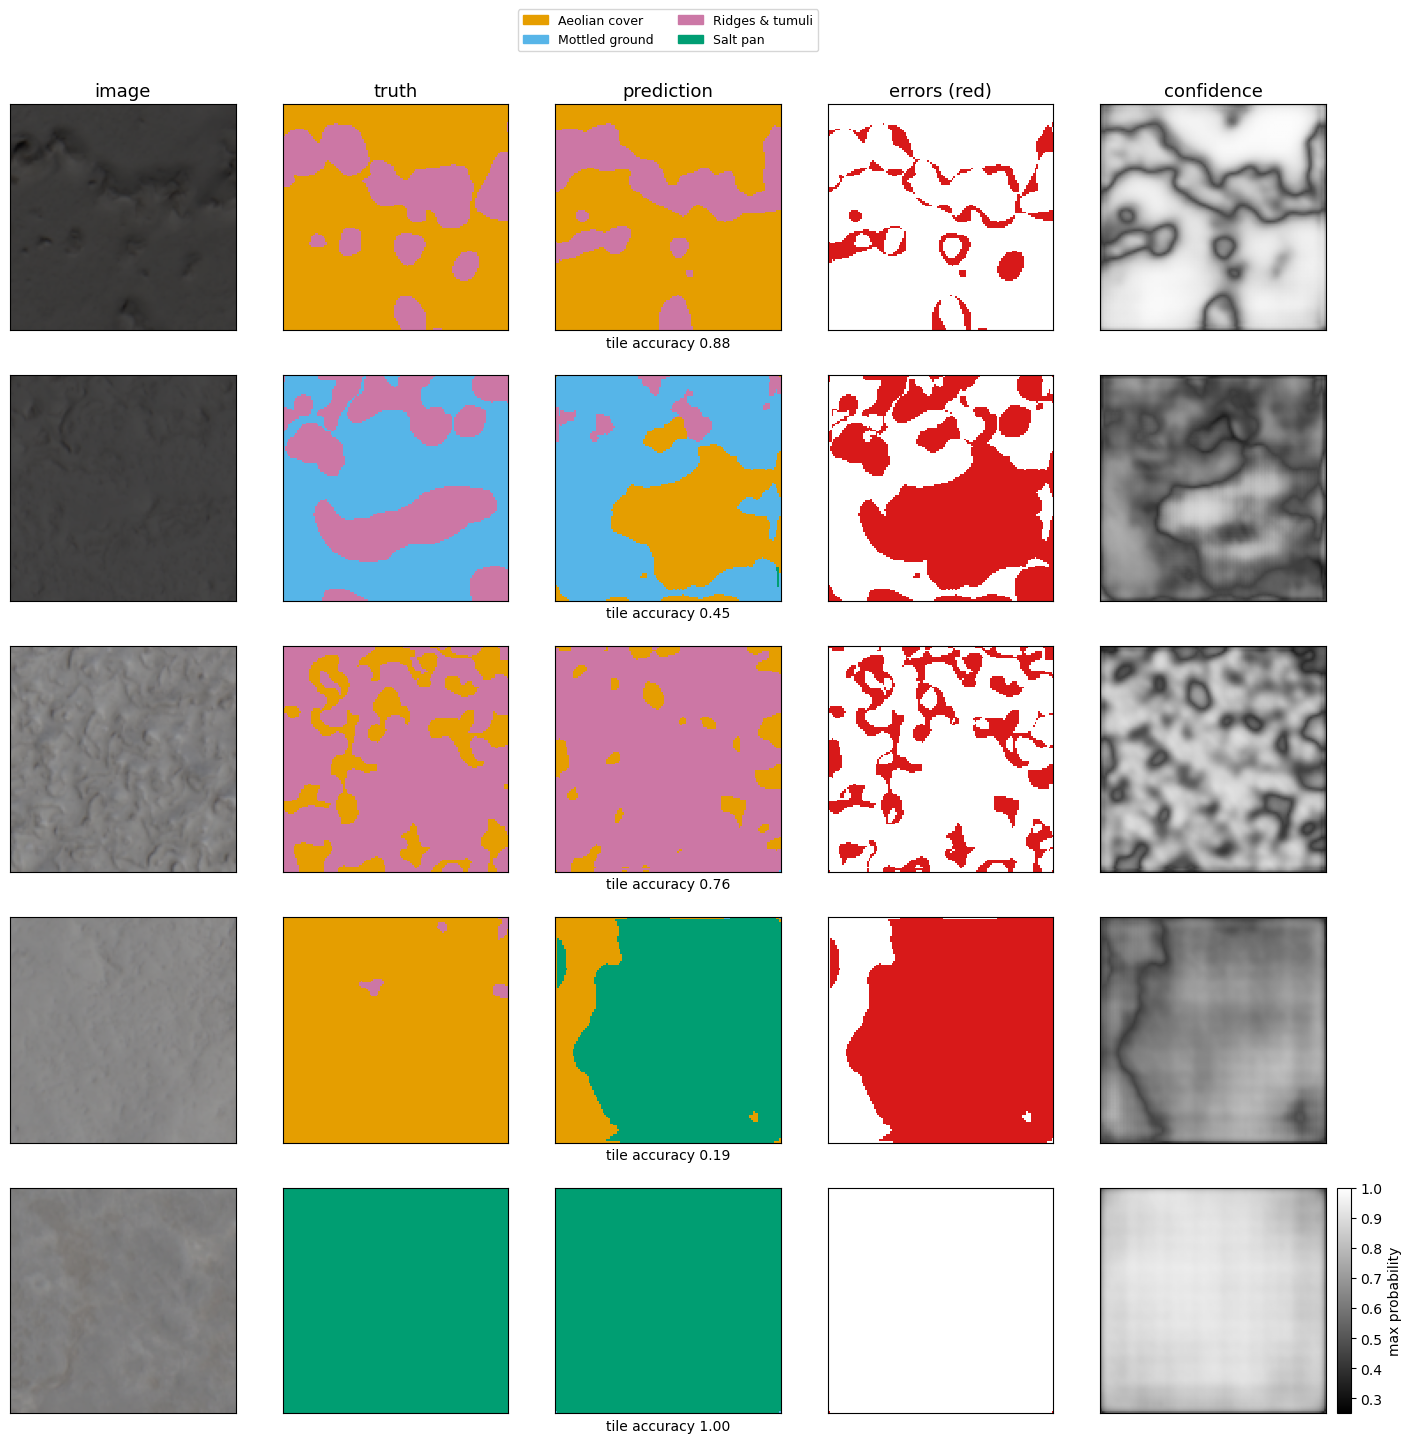

In [25]:
def show_predictions(model, dataset, ids):
    x = torch.stack([dataset[i][0] for i in ids])
    prob = predict(model, x)
    conf, pred = prob.max(1)
    cols = ['image', 'truth', 'prediction', 'errors (red)', 'confidence']
    fig, ax = plt.subplots(len(ids), 5, figsize=(17, 3.4 * len(ids)))
    for r, i in enumerate(ids):
        img, msk = dataset[i]
        msk, p = msk.numpy(), pred[r].numpy()
        err = np.ones(msk.shape + (3,)); err[p != msk] = [0.85, 0.1, 0.1]; err[msk == IGNORE] = 0.6
        valid = msk != IGNORE
        ax[r, 0].imshow(to_display(img))
        ax[r, 1].imshow(colorize(msk), interpolation='nearest')
        ax[r, 2].imshow(colorize(p), interpolation='nearest')
        ax[r, 3].imshow(err, interpolation='nearest')
        im = ax[r, 4].imshow(conf[r], cmap='gray', vmin=0.25, vmax=1)
        ax[r, 2].set_xlabel(f'tile accuracy {(p == msk)[valid].mean():.2f}' if valid.any() else '')
    for j, c in enumerate(cols): ax[0, j].set_title(c, fontsize=13)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    show_legend(ax[0, 2], CLASSES, COLORS, loc='upper center', bbox_to_anchor=(0.5, 1.45), ncol=2, fontsize=9)
    fig.colorbar(im, cax=ax[-1, 4].inset_axes([1.05, 0, 0.06, 1]), label='max probability')
    plt.show()

# 🔧 Try it: change these numbers to look at other test tiles (0 to len(test_ds)-1)
show_predictions(model, test_ds, ids=[0, 7, 21, 33, 60])

---
## Step 7: Look inside, seeing the "flow" through the U-Net

Below, one test tile passes through the trained network. For each stage we show its **5 most active feature maps** (channels), each a grayscale image of where that "detector" fires.

* Going **down** the encoder, maps get **smaller and more abstract**: from edges and brightness to "ridge-like texture here".
* At the **bottleneck** each feature pixel summarizes roughly 2 m × 2 m of ground.
* Going **up** the decoder, the skip connections bring back sharp detail, and maps start to look like the **terrain units**.
* The last column shows the 4 class scores (logits) → the final map.

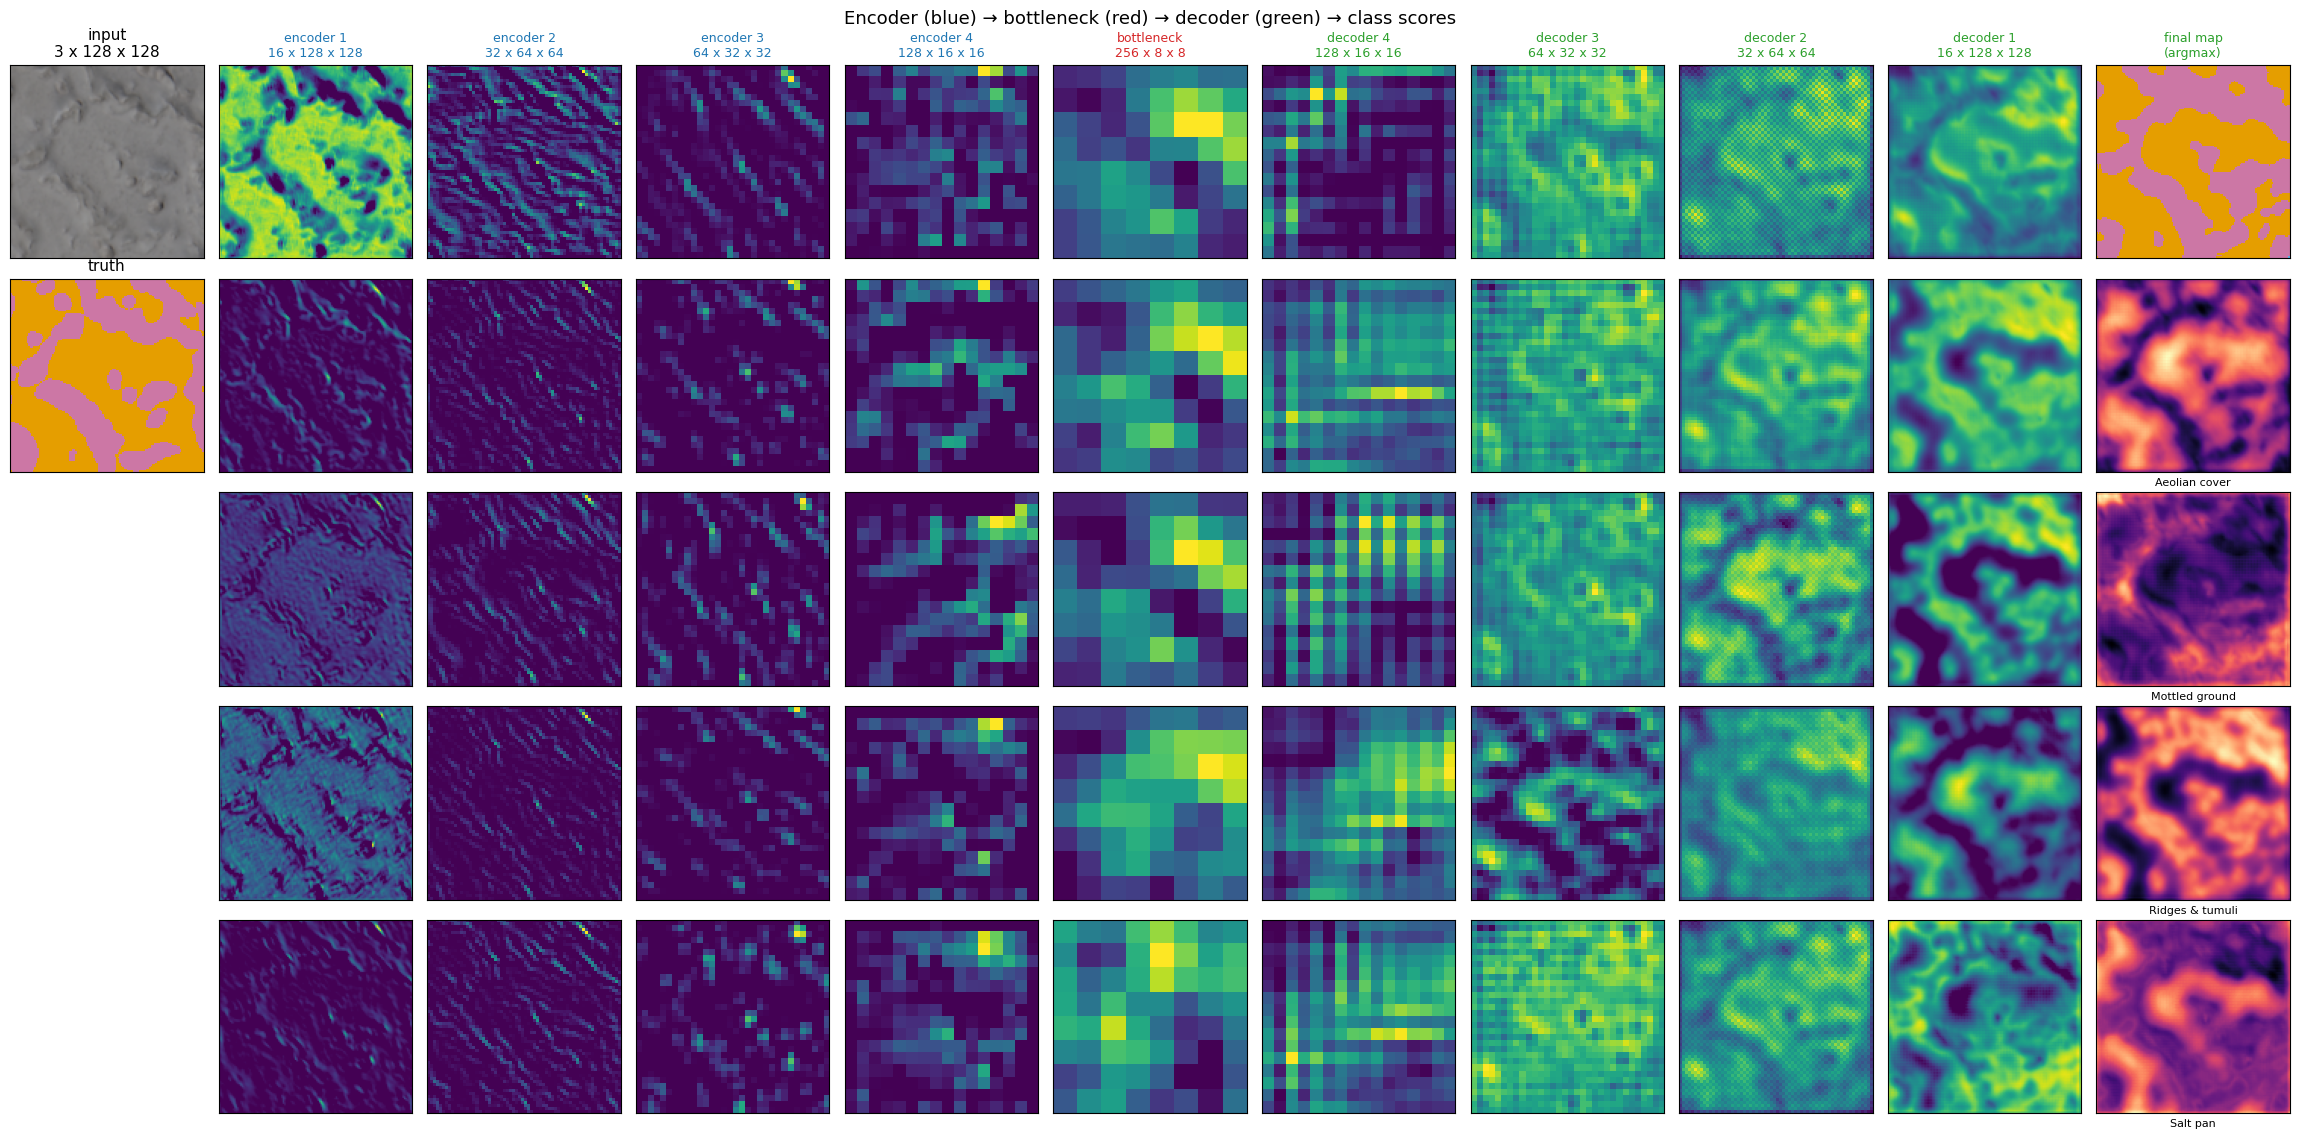

In [ ]:
def show_flow(model, img, msk, n_ch=NUM_CLASSES):
    model.eval()
    with torch.no_grad():
        _, feats = model(img[None].to(device), return_features=True)
    stages = [k for k in feats if k != 'input']
    fig, ax = plt.subplots(n_ch + 1, len(stages) + 1, figsize=(2.1 * (len(stages) + 1), 2.3 * (n_ch + 1)))
    ax[0, 0].imshow(to_display(img)); ax[0, 0].set_title('input\n3 x %d x %d' % tuple(img.shape[1:]))
    ax[1, 0].imshow(colorize(msk.numpy()), interpolation='nearest'); ax[1, 0].set_title('truth')
    for j, name in enumerate(stages, start=1):
        f = feats[name][0].cpu()
        ax[0, j].set_title(f'{name}\n{f.shape[0]} x {f.shape[1]} x {f.shape[2]}', fontsize=9,
                           color='C0' if 'enc' in name else 'C3' if 'bott' in name else 'C2')
        if name.startswith('output'):
            ax[0, j].imshow(colorize(f.argmax(0).numpy()), interpolation='nearest')
            ax[0, j].set_title('final map\n(argmax)', fontsize=9)
            for r in range(1, NUM_CLASSES + 1):
                ax[r, j].imshow(f[r - 1], cmap='magma'); ax[r, j].set_xlabel(CLASSES[r - 1], fontsize=8)
        else:
            strongest = f.abs().mean((1, 2)).argsort(descending=True)[:n_ch + 1]   # most active channels
            for r in range(n_ch + 1):
                ax[r, j].imshow(f[strongest[r]], cmap='viridis')
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    for a in ax[2:, 0]: a.axis('off')
    fig.suptitle('Encoder (blue) → bottleneck (red) → decoder (green) → class scores', fontsize=13)
    plt.tight_layout(); plt.show()

show_flow(model, *test_ds[9]) # change the index to see different tiles

---
## Optional Step 8: Fine-tune a pretrained Transformer (SegFormer)

> This part is **optional**. It needs the `transformers` package (`pip install transformers`) and an internet connection to download pretrained weights (~15 MB). On a laptop CPU, 10 epochs take roughly 3 to 5 minutes, about the same per epoch as the U-Net.

### From CNNs to Vision Transformers, in one paragraph
A CNN looks at the image through small windows (3×3 convolutions) and only gradually builds up a wide view. A **Vision Transformer (ViT)** cuts the image into **patches**, turns each patch into a vector (a "token", like a word in a sentence), and uses **self-attention** to let *every patch look at every other patch* from the very first layer. For each patch, attention asks "which other patches are relevant to me?" and mixes their information accordingly. This gives transformers a **global view** of the scene, at the cost of needing much more training data, which is why we start from a model **pretrained** on millions of everyday images and **fine-tune** it on our terrain.

<center><img src="../files/vit_architecture.png" alt="ViT architecture" width="600"></center>

### SegFormer
**SegFormer** ([Xie et al., 2021](https://arxiv.org/abs/2105.15203)) is an efficient transformer designed for segmentation:
* a **hierarchical transformer encoder** produces features at 1/4, 1/8, 1/16 and 1/32 of the input resolution (much like the U-Net encoder levels);
* a very light **all-MLP decoder** merges the four levels and predicts a map at 1/4 resolution, which we upsample to full size.

<center><img src="../files/segformer_architecture.jpg" alt="SegFormer architecture" width="750"></center>

We use the smallest version, **MiT-b0** (about 3.7 M parameters, pretrained on ImageNet), swap its output layer for our 4 classes, and train it with **exactly the same data, loss, and training loop** as the U-Net, so the comparison is fair.

**Transfer learning detail:** the pretrained weights expect images normalized with *ImageNet* statistics, so a small wrapper converts our normalization to theirs.

In [34]:
RUN_SEGFORMER = True     # <- set to True to run this optional section
SEGFORMER_EPOCHS = 10
SEGFORMER_LR = 1e-3       # transformers usually prefer a smaller learning rate than CNNs

W1111 20:34:50.131000 19474 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


SegFormer parameters: 3,715,172 (U-Net: 1,942,628)
epoch  1/10 | train loss 0.824 acc 0.675 | val loss 0.892 acc 0.705 mIoU 0.519 | 28.3s  <- best so far, saved
epoch  2/10 | train loss 0.723 acc 0.702 | val loss 0.818 acc 0.668 mIoU 0.490 | 19.6s
epoch  3/10 | train loss 0.701 acc 0.706 | val loss 0.876 acc 0.616 mIoU 0.419 | 19.6s
epoch  4/10 | train loss 0.594 acc 0.749 | val loss 0.531 acc 0.793 mIoU 0.675 | 19.6s  <- best so far, saved
epoch  5/10 | train loss 0.530 acc 0.776 | val loss 0.800 acc 0.677 mIoU 0.531 | 19.5s
epoch  6/10 | train loss 0.496 acc 0.787 | val loss 0.459 acc 0.796 mIoU 0.689 | 19.7s  <- best so far, saved
epoch  7/10 | train loss 0.443 acc 0.811 | val loss 0.438 acc 0.818 mIoU 0.704 | 19.6s  <- best so far, saved
epoch  8/10 | train loss 0.398 acc 0.830 | val loss 0.370 acc 0.838 mIoU 0.742 | 19.6s  <- best so far, saved
epoch  9/10 | train loss 0.389 acc 0.833 | val loss 0.350 acc 0.849 mIoU 0.757 | 19.7s  <- best so far, saved
epoch 10/10 | train loss 0.3

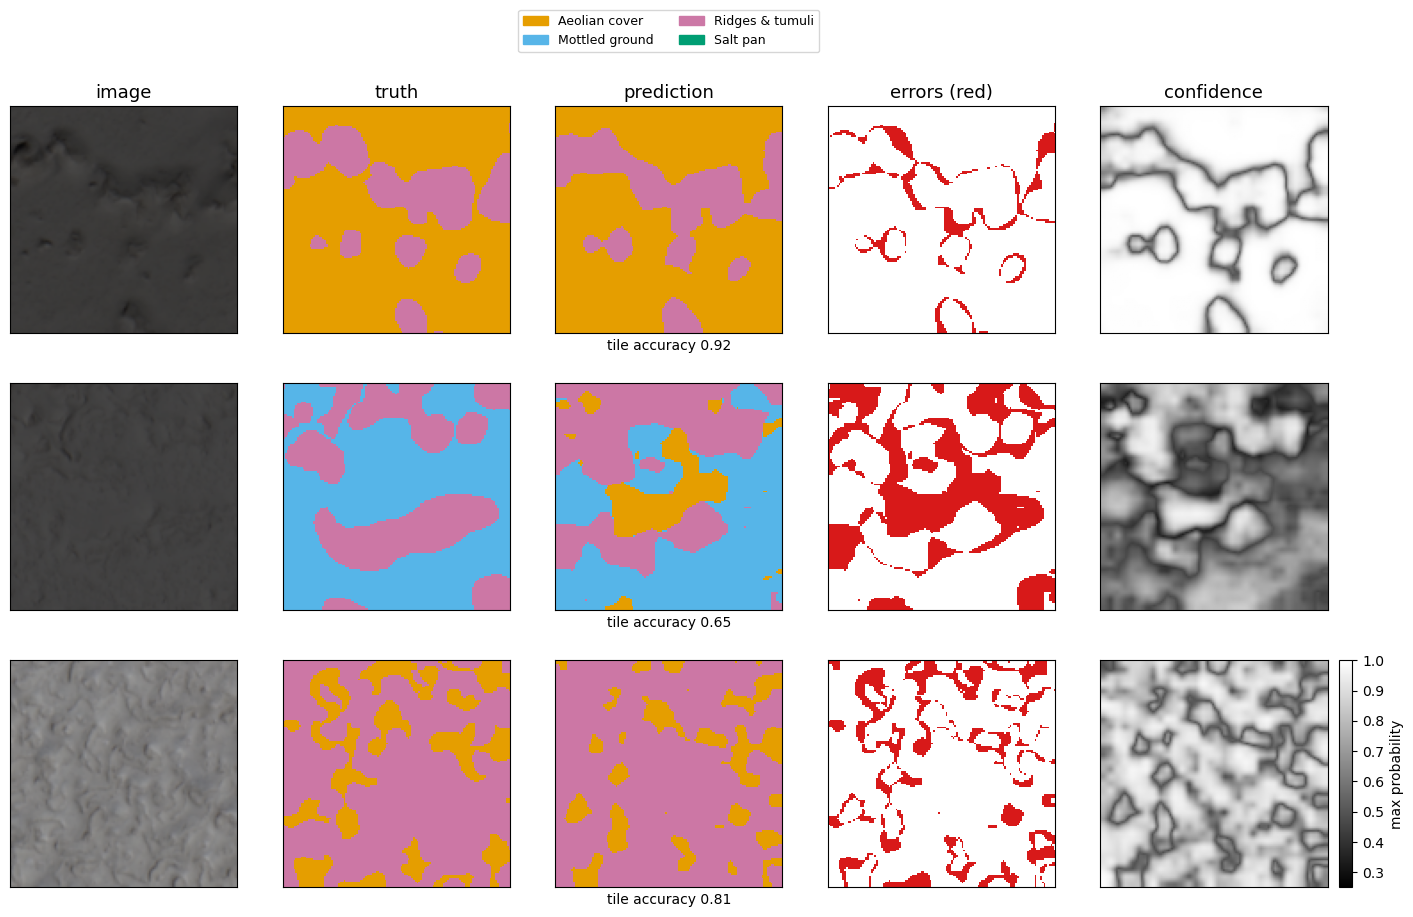

In [36]:
if RUN_SEGFORMER:
    from transformers import SegformerForSemanticSegmentation
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()   # keep the output tidy

    class SegFormerWrapper(nn.Module):
        # Makes the Hugging Face SegFormer behave like our U-Net: image in -> full-size logits out
        def __init__(self, num_classes):
            super().__init__()
            self.net = SegformerForSemanticSegmentation.from_pretrained(
                'nvidia/mit-b0', num_labels=num_classes)
            self.register_buffer('ours_mean', torch.tensor(MEAN, dtype=torch.float32).view(1, 3, 1, 1))
            self.register_buffer('ours_std',  torch.tensor(STD,  dtype=torch.float32).view(1, 3, 1, 1))
            self.register_buffer('imnet_mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
            self.register_buffer('imnet_std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        def forward(self, x):
            x = x * self.ours_std + self.ours_mean               # undo our normalization -> 0..1
            x = (x - self.imnet_mean) / self.imnet_std           # apply ImageNet normalization
            logits = self.net(pixel_values=x).logits             # (B, C, H/4, W/4)
            return F.interpolate(logits, size=x.shape[-2:], mode='bilinear', align_corners=False)

    torch.manual_seed(SEED)
    segformer = SegFormerWrapper(NUM_CLASSES).to(device)
    print(f'SegFormer parameters: {sum(p.numel() for p in segformer.parameters()):,} '
          f'(U-Net: {sum(p.numel() for p in model.parameters()):,})')

    SEGFORMER_PATH = f'{MODEL_DIR}/segformer_seg.pt'
    seg_history = train(segformer, SEGFORMER_EPOCHS, SEGFORMER_LR, SEGFORMER_PATH)
    segformer.load_state_dict(torch.load(SEGFORMER_PATH, map_location=device))
    _, seg_scores, _ = evaluate(segformer, test_loader, loss_fn)

    # Side-by-side comparison on the test set
    print(f'\n{"":<18}{"U-Net":>10}{"SegFormer":>12}')
    print(f'{"pixel accuracy":<18}{test_scores["acc"]:>10.3f}{seg_scores["acc"]:>12.3f}')
    print(f'{"mean IoU":<18}{test_scores["miou"]:>10.3f}{seg_scores["miou"]:>12.3f}')
    for c, name in enumerate(CLASSES):
        print(f'{"IoU " + name:<18}{test_scores["iou"][c]:>10.3f}{seg_scores["iou"][c]:>12.3f}')

    show_predictions(segformer, test_ds, ids=[0, 7, 21])
else:
    print('Optional SegFormer section skipped (set RUN_SEGFORMER = True to run it).')

---
## Summary
* **Semantic segmentation** = classification at every pixel; the label is a **mask** of class codes.
* Preparing the data (grouping classes, an *ignore* label, nearest-neighbor resizing of masks, joint augmentation) is half the work.
* A **U-Net** encodes context on the way down, decodes on the way up, and uses **skip connections** to keep boundaries sharp.
* Training minimizes **pixel-wise cross-entropy**; maps are judged with **IoU** and the **confusion matrix**, not accuracy alone.
* Errors are often geologically meaningful: gradational contacts and look-alike surfaces are hard for humans too.

## References
1. Ronneberger, O., Fischer, P., Brox, T. (2015). [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597).
2. Long, J., Shelhamer, E., Darrell, T. (2015). [Fully Convolutional Networks for Semantic Segmentation](https://arxiv.org/abs/1411.4038).
3. Dosovitskiy, A., et al. (2020). [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929).
4. Xie, E., et al. (2021). [SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers](https://arxiv.org/abs/2105.15203).
5. Vaswani, A., et al. (2017). [Attention Is All You Need](https://arxiv.org/abs/1706.03762).
6. Warren-Rhodes, K. A., Phillips, M. S., et al. (2023). Orbit-to-ground framework to decode and predict biosignature patterns in terrestrial analogues. *Nature Astronomy*. Dataset: [Zenodo 7384288](https://zenodo.org/records/7384288).